<a href="https://colab.research.google.com/github/mohib08/data_augmentation_project/blob/main/Diffusion_Occlusion_Augmentation_YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys

print("Python version:", sys.version)

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))

except ImportError:
    print("PyTorch is not installed.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
%pip install -q "diffusers==0.35.1" "transformers==4.46.3" "accelerate==1.2.1" safetensors

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import torch
import diffusers
import transformers

from transformers import CLIPImageProcessor
from diffusers import StableDiffusionPipeline

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("All imports successful!")
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Diffusers: 0.35.1
Transformers: 4.46.3
All imports successful!
GPU: Tesla T4


In [ ]:
import torch
from diffusers import StableDiffusionPipeline
import matplotlib.pyplot as plt

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

print("Stable Diffusion loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

...

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Stable Diffusion loaded successfully!


  0%|          | 0/25 [00:00<?, ?it/s]

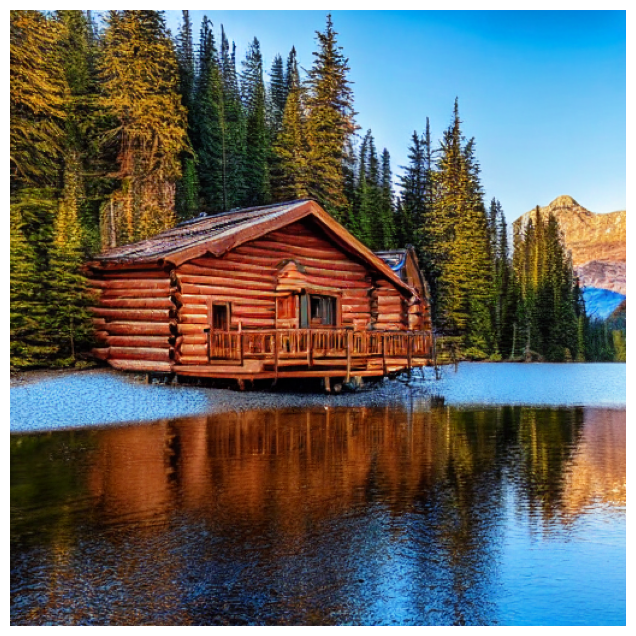

In [ ]:
prompt = "A small wooden cabin beside a lake in the mountains, sunrise, realistic photography"

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5,
    height=512,
    width=512
).images[0]

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
# This cell is just for learning – you don't need to run it every time

# When we generate an image, Stable Diffusion works in a compressed "latent" space.
# The latent is much smaller than the final image (usually 64x64 instead of 512x512).

with torch.no_grad():
    print("Latent shape is typically: (batch, 4, 64, 64)")

Latent shape is typically: (batch, 4, 64, 64)


  0%|          | 0/30 [00:00<?, ?it/s]

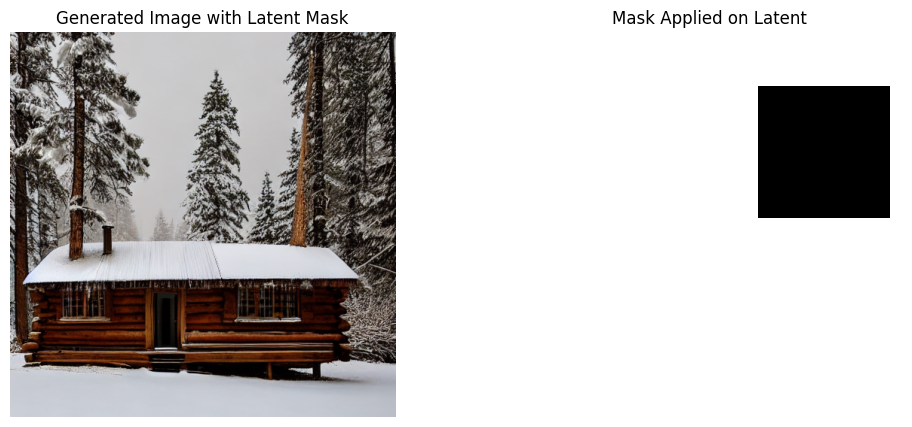

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

def apply_random_mask_to_latent(latent, mask_ratio=0.35):
    """
    Applies a random rectangular mask to a latent tensor.
    The masked region is replaced with random noise.
    """
    b, c, h, w = latent.shape

    mask = torch.ones_like(latent)

    mask_h = max(1, int(h * mask_ratio))
    mask_w = max(1, int(w * mask_ratio))

    top = torch.randint(0, h - mask_h + 1, (1,)).item()
    left = torch.randint(0, w - mask_w + 1, (1,)).item()

    mask[:, :, top:top + mask_h, left:left + mask_w] = 0.0

    noise = torch.randn_like(latent)
    masked_latent = latent * mask + noise * (1 - mask)

    return masked_latent, mask


# Prompt
prompt = "A small wooden cabin in a snowy forest, warm light glowing through the windows, gentle snowfall, blue winter twilight, realistic photography"

# Create initial random noise
generator = torch.Generator(device="cuda").manual_seed(42)

latents = torch.randn(
    (1, 4, 64, 64),
    generator=generator,
    device="cuda",
    dtype=torch.float16
)

# Apply the random mask
masked_latents, mask = apply_random_mask_to_latent(
    latents,
    mask_ratio=0.35
)

# Scale latents according to the scheduler
masked_latents = masked_latents * pipe.scheduler.init_noise_sigma

# Generate image
with torch.inference_mode():
    image = pipe(
        prompt,
        latents=masked_latents,
        num_inference_steps=30,
        guidance_scale=7.5,
        height=512,
        width=512
    ).images[0]

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Generated Image with Latent Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
plt.title("Mask Applied on Latent")
plt.axis("off")

plt.show()